**CSI 4106 Introduction to Artificial Intelligence**  
*Assignment 2: Mission Interruption Prediction with Classical Models*  
*Due: October 26, 2026, at 11 PM*

# Identification

Report title: Mission Interruption Prediction with Classical Models

# 1. Data and objective

The objective is to predict whether an autonomous underwater vehicle
returns before completing its planned survey. The positive class is
`mission_interrupted=1`.

- [Assignment 2 data
  directory](https://github.com/turcotte/csi4106-f26/tree/main/assignments-data/a2)
- [asrc_missions_complete.csv](https://raw.githubusercontent.com/turcotte/csi4106-f26/main/assignments-data/a2/asrc_missions_complete.csv)
- [asrc_missions_cleaned.csv](https://raw.githubusercontent.com/turcotte/csi4106-f26/main/assignments-data/a2/asrc_missions_cleaned.csv)
- [asrc_missions_hidden.csv](https://raw.githubusercontent.com/turcotte/csi4106-f26/main/assignments-data/a2/asrc_missions_hidden.csv)

Consult the assignment handout for the data relationships, experimental
constraints, required grids, and submission format.

# 2. Classical machine-learning study

2.1 Load the data and establish the experimental protocol

2.1.1: 
Load the complete and cleaned labelled datasets. Local copies may be
reused, but the notebook must obtain an unavailable source file from its
supplied URL without a manual upload. Report their shapes and the first
five complete rows. Verify that their columns, row order, and response
correspond. 

2.1.2: 
Separate the complete predictors and response, then create
the required stratified 80/20 split with `random_state=4106`. Report
class counts and proportions for the complete data and both partitions.

In [333]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dfClean = pd.read_csv("https://raw.githubusercontent.com/turcotte/csi4106-f26/refs/heads/main/assignments-data/a2/asrc_missions_cleaned.csv")
dfComp = pd.read_csv("https://raw.githubusercontent.com/turcotte/csi4106-f26/refs/heads/main/assignments-data/a2/asrc_missions_complete.csv")

## 2.1.1 Computation

dfClean first five rows and shape

In [334]:
dfClean.head()

,planned_depth_m,descent_current_speed_m_s,water_temperature_c,sonar_noise_db,navigation_drift_m,battery_health_pct,thruster_vibration_mm_s,missions_since_service,vehicle_class,seabed_terrain,maintenance_grade,firmware_current,mission_interrupted
0,1400.0,0.55,3.3,66.0,10.4,87.0,3.1,14,compact,ridge,good,1,0
1,2700.0,0.68,3.0,78.5,49.9,83.0,3.9,4,heavy_duty,vent_field,good,1,1
2,2870.0,0.15,3.6,78.7,5.8,92.0,5.2,10,survey,vent_field,fair,1,1
3,2840.0,0.39,2.5,77.3,54.6,89.0,3.9,9,survey,trench,good,1,0
4,2430.0,0.34,2.8,77.8,8.7,89.0,3.4,8,heavy_duty,vent_field,excellent,1,0


In [335]:
dfClean.shape

(6371, 13)

dfComplete first five rows and shape

In [336]:
dfComp.head()

,planned_depth_m,descent_current_speed_m_s,water_temperature_c,sonar_noise_db,navigation_drift_m,battery_health_pct,thruster_vibration_mm_s,missions_since_service,vehicle_class,seabed_terrain,maintenance_grade,firmware_current,mission_interrupted
0,1400.0,0.55,3.3,66.0,10.4,87.0,3.1,14,compact,ridge,good,1,0
1,2700.0,0.68,3.0,78.5,49.9,83.0,3.9,4,heavy_duty,vent_field,good,1,1
2,2870.0,0.15,3.6,78.7,5.8,92.0,5.2,10,survey,vent_field,fair,1,1
3,2840.0,0.39,2.5,77.3,54.6,89.0,3.9,9,survey,trench,good,1,0
4,2430.0,0.34,2.8,77.8,8.7,89.0,3.4,8,heavy_duty,vent_field,excellent,1,0


In [337]:
dfComp.shape

(6371, 13)

Column and rows check for both datasets

In [338]:
dfClean.columns.equals(dfComp.columns)

True

In [339]:
dfClean.index.equals(dfComp.index)

True

Response check for both datasets

In [340]:
dfClean["mission_interrupted"].value_counts() == dfComp["mission_interrupted"].value_counts()

mission_interrupted
0    True
1    True
Name: count, dtype: bool

## 2.1.1 Interpretation

Dataset composition analysis. The complete dataset is a true copy of the clean dataset, they have the same shape, same column names and same row values. They also have the same amount of 0's and 1's for mission_interrupted. These datasets being equivalent will be useful for the later tasks in this assignment.

## 2.1.2 Computation

In [341]:
from sklearn.model_selection import train_test_split

Stratified split on complete data

In [342]:
targetCol = "mission_interrupted"

X = dfComp.drop(columns=[targetCol])
y = dfComp[targetCol]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=4106, stratify=y
)

Save indices for direct reference in later Task 2.6

In [343]:
train_indices = X_train.index
test_indices = X_test.index

Class counts and proportions on complete data

In [344]:
y.value_counts()

mission_interrupted
0    4295
1    2076
Name: count, dtype: int64

In [345]:
y.value_counts(normalize=True)

mission_interrupted
0    0.674148
1    0.325852
Name: proportion, dtype: float64

Class counts and proportions on training partition

In [346]:
y_train.value_counts()

mission_interrupted
0    3435
1    1661
Name: count, dtype: int64

In [347]:
y_train.value_counts(normalize=True)

mission_interrupted
0    0.674058
1    0.325942
Name: proportion, dtype: float64

Class counts and proportions on testing partition

In [348]:
y_test.value_counts()

mission_interrupted
0    860
1    415
Name: count, dtype: int64

In [349]:
y_test.value_counts(normalize=True)

mission_interrupted
0    0.67451
1    0.32549
Name: proportion, dtype: float64

## 2.1.2 Interpretation

Class count split analysis. From what I understand, class count refers to the target mission_interrupted. The training partition's class count is seen to be split at 67.4% True and 32.6% False, whereas the testing partition's class count has roughly the same proportions at 67.5% True and 32.5% False. This shows that the dataset's training and testing partitions are balanced equally.

## 2.2 Construct leakage-safe preprocessing pipelines

2.2.1: Identify the numerical, nominal, ordinal, and binary predictors and
present the proposed preprocessing in a compact table. 

2.2.2: Construct the required `ColumnTransformer` and model pipelines. Explain the choices,
how later data with an otherwise valid category absent from a training
fold can be transformed, and how the design prevents data leakage during
cross-validation.

## 2.2.1 Computations

In [350]:
X.head()

,planned_depth_m,descent_current_speed_m_s,water_temperature_c,sonar_noise_db,navigation_drift_m,battery_health_pct,thruster_vibration_mm_s,missions_since_service,vehicle_class,seabed_terrain,maintenance_grade,firmware_current
0,1400.0,0.55,3.3,66.0,10.4,87.0,3.1,14,compact,ridge,good,1
1,2700.0,0.68,3.0,78.5,49.9,83.0,3.9,4,heavy_duty,vent_field,good,1
2,2870.0,0.15,3.6,78.7,5.8,92.0,5.2,10,survey,vent_field,fair,1
3,2840.0,0.39,2.5,77.3,54.6,89.0,3.9,9,survey,trench,good,1
4,2430.0,0.34,2.8,77.8,8.7,89.0,3.4,8,heavy_duty,vent_field,excellent,1


Base preprocessing scheme:

In [351]:
numerical = ["planned_depth_m", 
             "descent_current_speed_m_s", 
             "water_temperature_c", 
             "sonar_noise_db", 
             "navigation_drift_m", 
             "battery_health_pct",
             "thruster_vibration_mm_s",
             "missions_since_service"
            ]
## Proposed numerical preprocessing: StandardScaler()
nominal = ["vehicle_class",
           "seabed_terrain"
          ]
## Proposed nominal preprocessing: OneHotEncoder()
ordinal = ["maintenance_grade"]
## Proposed ordinal preprocessing: OrdinalEncoder(categories=[])
binary = ["firmware_current"]
## Proposed binary preprocessing: OneHotEncoder(handle_unknown='ignore')

In [352]:
X["firmware_current"].dtype

dtype('int64')

## 2.2.2 Computations

In [353]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

Maintenance_grade ordinal scaling values

In [354]:
dfComp['maintenance_grade'].value_counts()

maintenance_grade
good         2571
excellent    2174
fair         1193
poor          433
Name: count, dtype: int64

Base pipeline and transformers:

In [355]:
basePreprocessor = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'), nominal),
        ('onehotBin', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), binary),
        ('scaler', StandardScaler(), numerical),
        ('ord', OrdinalEncoder(categories=[['poor', 'fair', 'good', 'excellent']]), ordinal)
    ]
)
# LEGACY - See 2.4.1 Interpretation
# treePreprocessor = ColumnTransformer(
#     transformers=[
#         ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'), nominal),
#         ('onehotBin', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), binary),
#         ('numerical', 'passthrough', numerical),
#         ('ord', OrdinalEncoder(categories=[['poor', 'fair', 'good', 'excellent']]), ordinal)
#     ]
# )

## Example of Pipeline, not to be reused across all models since it was init. with LogReg().
basePipeline = Pipeline([
    ('basePreprocessor', basePreprocessor),
    ('classifier', LogisticRegression())
])

## 2.2.2 Interpretation

Column type analysis & Justification of the encoding and scaling choices.

Looking at the type of the majority of the values in each row led me to conclude my choices. 

### Attributes and columns:
- Numerical attributes all have different scales so `StandardScaler` would bring them all together, which would help ease out the understanding of distance and put all attributes relative to one another on the same scale.
- Nominal attributes (otherwise known as Categorical) were easy to identify as most of their values were a string part of a set of strings with little-to-no distance notion between them. `OneHotEncoder` is the norm for converting nomial attributes to something models can use mathmatically. Added with `drop = 'first'` to optimize the vector length of the encoding.
- Binary / Boolean attributes were detected through value analysis where all found values were [0,1]. firmware_current fit that description but its type when checked returned int64, not bool. This means, the row is unrestricted to only 0's and 1's and could theoretically hold other integers. This column needed to be restrained, thus the addition of the `OneHotEncoder` with `handle_unknown = ignore` to ignore all other values other than binaries.
- maintenance_grade pointed towards an Ordinal scheme of data where numbers 0-3 represented how maintained the vehicle was at that date and time. This led me to encode this attribute with `OrdinalEncoder` with a specified `categories=['poor', 'fair', 'good', 'excellent']` to ensure these values were in order in relative distance. ***Note***: Later trials of StandardEncoder(ing) this Ordinal scheme to see if fitting the 0-3 distance scale on a normal scale would help models returned worse results, which was super surprising. It was therefore left out, but considered nonetheless.
- Since KNN is distance-based, standardizing the ordinal `maintenance_grade` feature after encoding was tested. However, this slightly reduced CV performance, with F1 decreasing from 0.667 to 0.659 and ROC AUC from 0.841 to 0.839. The original preprocessing was therefore retained. The tested scaling implementation and results are not included in the notebook since they performed worse than the retained approach.

### Preprocessors and Pipelines:
- The basePipeline initialization was with `LogisiticRegression`, we will be able to re-use basePipeline as the Pipeline for the LogisticRegression contrustion in step 2.3
- The trial of a treePreprocessor fitting Decision tree and Random Forest models was unsuccessful and retired as legacy. With the hopes of optimizing compute and minimizing model friction, this preprocessor would not bother scaling numerical attributes `numerical, passthrough`, as this is relatively unnecessary for a model that splits. It's splits would simply have different values, but hold the same meaning scaled and unscaled. This returned worse performance.

## 2.3 Evaluate baselines and default models

2.3.1: Evaluate the always-positive baseline.

2.3.2: Evaluate the three classifiers studied in class, and the required random-forest extension using the same folds. Report mean and standard deviation for precision, recall, F1, and ROC
AUC. Consult the handout for the short introduction to random forest.

## 2.3.1 Computations

Same cross-validation folds for all models

In [356]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=4106
)

Same scoring for all models

In [357]:
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

In [358]:
from sklearn.dummy import DummyClassifier

In [359]:
dumbClf = DummyClassifier(strategy='constant', constant=1)

dumb_scores = cross_validate(
    dumbClf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = dumb_scores[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy: 0.326 ± 0.000
precision: 0.326 ± 0.000
recall: 1.000 ± 0.000
f1: 0.492 ± 0.000
roc_auc: 0.500 ± 0.000


## 2.3.1 Interpretation

The dummy classifier with `strategy='constant'` proved to be the easiest way to manipulate all predictions to a constant. This impacted the recall to be a perfect 1.0.

### The F1 baseline:
This dummy is able to show us that without learning anything at all, at a minimum mission_interrupted's 1 values can be predicted on average atleast 32.6% of the time, which translates to a minimum F1 baseline of 0.492. This means that without any learning, a dumb model can get ATLEAST a score of 0.492 in F1.

## 2.3.2 Computations

In [360]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

### Logisitc Regression

In [361]:
logreg = LogisticRegression(
    max_iter=1000,
    random_state=4106
)

logreg_pipeline = basePipeline

logreg_scores = cross_validate(
    logreg_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

logreg_results = {}

for metric in scoring:
    scores = logreg_scores[f"test_{metric}"]
    logreg_results[metric] = (scores.mean(), scores.std())

### Decision Tree

In [362]:
decision_tree = DecisionTreeClassifier(
    random_state=4106
)

decision_tree_pipeline = Pipeline([
    ("preprocessor", basePreprocessor),
    ("classifier", decision_tree)
])

decision_tree_scores = cross_validate(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

decision_tree_results = {}

for metric in scoring:
    scores = decision_tree_scores[f"test_{metric}"]
    decision_tree_results[metric] = (scores.mean(), scores.std())

### KNN

In [363]:
knn = KNeighborsClassifier()

knn_pipeline = Pipeline([
    ("preprocessor", basePreprocessor),
    ("classifier", knn)
])

knn_scores = cross_validate(
    knn_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

knn_results = {}

for metric in scoring:
    scores = knn_scores[f"test_{metric}"]
    knn_results[metric] = (scores.mean(), scores.std())

### Random Forest

In [364]:
random_forest = RandomForestClassifier(
    random_state=4106
)

random_forest_pipeline = Pipeline([
    ("preprocessor", basePreprocessor),
    ("classifier", random_forest)
])

random_forest_scores = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

random_forest_results = {}

for metric in scoring:
    scores = random_forest_scores[f"test_{metric}"]
    random_forest_results[metric] = (scores.mean(), scores.std())

### All results concatenated

In [365]:
all_results = {
    "Logistic Regression": logreg_results,
    "Decision Tree": decision_tree_results,
    "KNN": knn_results,
    "Random Forest": random_forest_results
}

table = {}

for model, results in all_results.items():
    table[model] = {
        metric: f"{mean:.3f} ± {std:.3f}"
        for metric, (mean, std) in results.items()
    }

results_df = pd.DataFrame(table).T

print(results_df)

                          accuracy      precision         recall  \
Logistic Regression  0.785 ± 0.013  0.739 ± 0.034  0.526 ± 0.022   
Decision Tree        0.745 ± 0.006  0.604 ± 0.009  0.629 ± 0.014   
KNN                  0.801 ± 0.011  0.759 ± 0.019  0.569 ± 0.023   
Random Forest        0.826 ± 0.007  0.803 ± 0.016  0.619 ± 0.014   

                                f1        roc_auc  
Logistic Regression  0.614 ± 0.023  0.787 ± 0.010  
Decision Tree        0.616 ± 0.009  0.715 ± 0.006  
KNN                  0.650 ± 0.021  0.822 ± 0.016  
Random Forest        0.699 ± 0.012  0.870 ± 0.013  


## 2.3.2 Interpretation

Interpret the baseline results and the relative strengths and weaknesses of the four default models.

After constructing, pipelining, cross-validating and scoring all 4 models, the results are in.
#### `LogisiticRegression`:
The Logistic Regression model is one of the weaker performing models, with an F1 score of 0.614. A strength of Logistic Regression is that it is simple and works well when there are clear and relatively linear relationships between the features and the target. However, this simplicity can also be a weakness. Its lower performance suggests that the relationships in this dataset may be too complex or nonlinear for Logistic Regression to capture as well as the other models.
#### `DecisionTree`:
The Decision Tree also performs relatively weakly, with an F1 score of 0.616. Its main strength is that it can capture nonlinear relationships by repeatedly splitting the data based on different features. However, a single Decision Tree can easily become too specific to the data it was trained on and may not generalize as well to new data. This could help explain why it is heavily outperformed by the Random Forest, which combines the results of many different Decision Trees.
#### `KNN`:
KNN performs better than Logistic Regression and the Decision Tree, reaching an F1 score of 0.650. Its strength is that it can find more complex patterns by comparing an observation to the observations that are closest to it. However, KNN relies heavily on distance, meaning that irrelevant features, feature scaling, or observations that do not form clear groups can hurt its performance. Its stronger result suggests that similar observations in this dataset may share some useful patterns, but these patterns were still not enough to outperform the Random Forest.
#### `RandomForest`:
The Random Forest is the best-performing model in precision by a wide margin and trails in second for recall. With an F1 score of 0.699, it is the overall best-performing baseline model. It overshadows the Decision Tree model because a Random Forest builds many Decision Trees and combines their predictions instead of relying on only one tree. This generally makes its predictions more stable and gives it a better chance of performing well on new data. Its stronger performance also suggests that the dataset may contain nonlinear relationships or interactions between features that the Random Forest is better able to capture. A weakness is that using many trees makes the model more complex, slower, and harder to interpret than a single Decision Tree or Logistic Regression.

## 2.4 Tune the models

Perform the required grid searches on the development partition. For
each model, report its best configuration and cross-validation metrics,
compare training and validation F1, and use compact tables or figures
that collectively show the effect of every searched hyperparameter.
Every interaction need not be displayed.

2.4.1: Logisitic Regression

2.4.2: Decision Tree

2.4.3: KNN

2.4.4: Random Forest

## 2.4.1 Computation

In [366]:
from sklearn.model_selection import GridSearchCV

### Logistic regression

In [367]:
logreg_param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10],
    'classifier__class_weight': [None, 'balanced']
}

logreg_grid_search = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=logreg_param_grid,
    scoring=scoring,
    refit='f1',
    return_train_score=True,
    cv=cv,
    n_jobs=-1
)

logreg_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.001, 0.01, ...], 'classifier__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'precision', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each

In [368]:
logreg_best_idx = logreg_grid_search.best_index_
logreg_results = logreg_grid_search.cv_results_

print("Logistic Regression")
print("---------------------------")

print("Best parameters:", logreg_grid_search.best_params_)

print("\nCV Results:")
print(f"Precision: {logreg_results['mean_test_precision'][logreg_best_idx]:.3f} ± {logreg_results['std_test_precision'][logreg_best_idx]:.3f}")
print(f"Recall:    {logreg_results['mean_test_recall'][logreg_best_idx]:.3f} ± {logreg_results['std_test_recall'][logreg_best_idx]:.3f}")
print(f"F1:        {logreg_results['mean_test_f1'][logreg_best_idx]:.3f} ± {logreg_results['std_test_f1'][logreg_best_idx]:.3f}")
print(f"ROC AUC:   {logreg_results['mean_test_roc_auc'][logreg_best_idx]:.3f} ± {logreg_results['std_test_roc_auc'][logreg_best_idx]:.3f}")

logreg_train_f1 = logreg_results['mean_train_f1'][logreg_best_idx]
logreg_cv_f1 = logreg_results['mean_test_f1'][logreg_best_idx]

print(f"\nMean Training F1: {logreg_train_f1:.3f}")
print(f"Train-CV F1 Gap:  {logreg_train_f1 - logreg_cv_f1:.3f}")

Logistic Regression
---------------------------
Best parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}

CV Results:
Precision: 0.580 ± 0.014
Recall:    0.692 ± 0.010
F1:        0.631 ± 0.009
ROC AUC:   0.788 ± 0.009

Mean Training F1: 0.633
Train-CV F1 Gap:  0.002


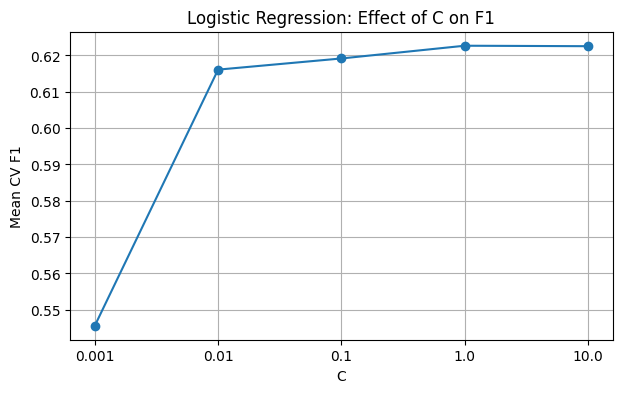

In [369]:
logreg_graph = pd.DataFrame(logreg_results)

logreg_f1_by_C = logreg_graph.groupby(
    'param_classifier__C'
)['mean_test_f1'].mean()

plt.figure(figsize=(7, 4))
plt.plot(logreg_f1_by_C.index.astype(str), logreg_f1_by_C.values, marker='o')

plt.xlabel('C')
plt.ylabel('Mean CV F1')
plt.title('Logistic Regression: Effect of C on F1')
plt.grid(True)
plt.show()

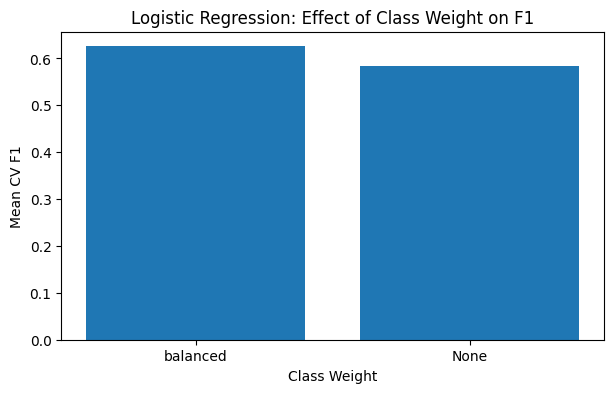

In [370]:
logreg_f1_by_weight = logreg_graph.groupby(
    'param_classifier__class_weight',
    dropna=False
)['mean_test_f1'].mean()

logreg_f1_by_weight.index = logreg_f1_by_weight.index.map(
    lambda x: 'None' if pd.isna(x) else str(x)
)

plt.figure(figsize=(7, 4))
plt.bar(logreg_f1_by_weight.index, logreg_f1_by_weight.values)

plt.xlabel('Class Weight')
plt.ylabel('Mean CV F1')
plt.title('Logistic Regression: Effect of Class Weight on F1')
plt.show()

## 2.4.1 `LogisiticRegression GridSearchCV` Interpretation

The GridSearchCV found C = 1 and class_weight = balanced as the best hyperparameters for Logistic Regression, resulting in an F1 score of 0.631. This is an improvement over the default Logistic Regression F1 of 0.614.

- Using balanced gives more importance to the minority class, which helps the model identify more positive cases. This is reflected by the relatively high recall of 0.692. The graph also shows that the balanced class weight performs better than using no class weighting.
- Performance increases as C approaches 1. There is very little improvement between C = 1 and C = 10, which suggests that increasing C beyond 1 provides no meaningful benefit.
- The mean training F1 is 0.633 compared with a cross-validation F1 of 0.631, giving a very small gap of 0.002. This suggests that the model's performance remains consistent on the validation folds.
- Overall, tuning improved Logistic Regression from an F1 of 0.614 to 0.631. The improvement is relatively small, but class balancing helped the model achieve better performance, particularly in recall.

### Decision tree

In [371]:
decision_tree_param_grid = {
    'classifier__max_depth': [3, 7, 12, 20, None],
    'classifier__min_samples_leaf': [1, 5, 10, 20, 50]
}

decision_tree_grid_search = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=decision_tree_param_grid,
    scoring=scoring,
    refit='f1',
    return_train_score=True,
    cv=cv,
    n_jobs=-1
)

decision_tree_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=4106))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [3, 7, ...], 'classifier__min_samples_leaf': [1, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'precision', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each f

In [372]:
decision_tree_best_idx = decision_tree_grid_search.best_index_
decision_tree_results = decision_tree_grid_search.cv_results_

print("Decision Tree")
print("---------------------------")

print("Best parameters:", decision_tree_grid_search.best_params_)

print("\nCV Results:")
print(f"Precision: {decision_tree_results['mean_test_precision'][decision_tree_best_idx]:.3f} ± {decision_tree_results['std_test_precision'][decision_tree_best_idx]:.3f}")
print(f"Recall:    {decision_tree_results['mean_test_recall'][decision_tree_best_idx]:.3f} ± {decision_tree_results['std_test_recall'][decision_tree_best_idx]:.3f}")
print(f"F1:        {decision_tree_results['mean_test_f1'][decision_tree_best_idx]:.3f} ± {decision_tree_results['std_test_f1'][decision_tree_best_idx]:.3f}")
print(f"ROC AUC:   {decision_tree_results['mean_test_roc_auc'][decision_tree_best_idx]:.3f} ± {decision_tree_results['std_test_roc_auc'][decision_tree_best_idx]:.3f}")

decision_tree_train_f1 = decision_tree_results['mean_train_f1'][decision_tree_best_idx]
decision_tree_cv_f1 = decision_tree_results['mean_test_f1'][decision_tree_best_idx]

print(f"\nMean Training F1: {decision_tree_train_f1:.3f}")
print(f"Train-CV F1 Gap:  {decision_tree_train_f1 - decision_tree_cv_f1:.3f}")

Decision Tree
---------------------------
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 10}

CV Results:
Precision: 0.705 ± 0.027
Recall:    0.600 ± 0.036
F1:        0.648 ± 0.025
ROC AUC:   0.810 ± 0.014

Mean Training F1: 0.778
Train-CV F1 Gap:  0.130


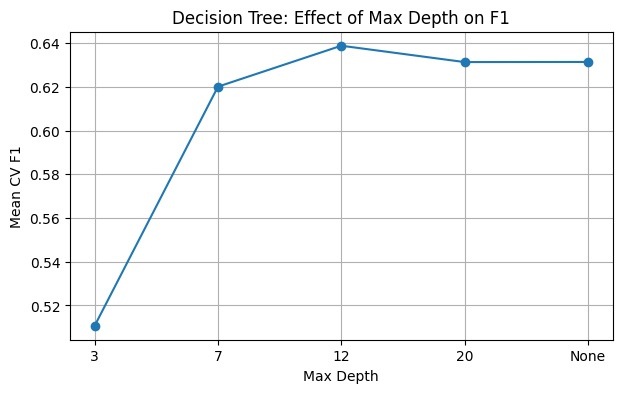

In [373]:
decision_tree_graph = pd.DataFrame(decision_tree_results)

decision_tree_f1_by_depth = decision_tree_graph.groupby(
    'param_classifier__max_depth',
    dropna=False
)['mean_test_f1'].mean()

decision_tree_f1_by_depth.index = decision_tree_f1_by_depth.index.map(
    lambda x: 'None' if pd.isna(x) else str(int(x))
)

plt.figure(figsize=(7, 4))
plt.plot(
    decision_tree_f1_by_depth.index,
    decision_tree_f1_by_depth.values,
    marker='o'
)

plt.xlabel('Max Depth')
plt.ylabel('Mean CV F1')
plt.title('Decision Tree: Effect of Max Depth on F1')
plt.grid(True)
plt.show()

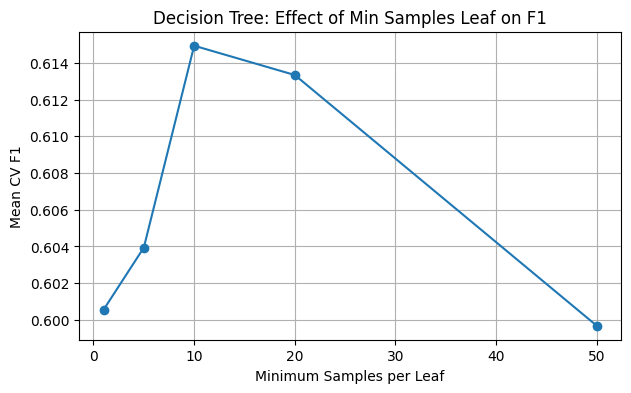

In [374]:
decision_tree_f1_by_leaf = decision_tree_graph.groupby(
    'param_classifier__min_samples_leaf'
)['mean_test_f1'].mean()

plt.figure(figsize=(7, 4))
plt.plot(
    decision_tree_f1_by_leaf.index,
    decision_tree_f1_by_leaf.values,
    marker='o'
)

plt.xlabel('Minimum Samples per Leaf')
plt.ylabel('Mean CV F1')
plt.title('Decision Tree: Effect of Min Samples Leaf on F1')
plt.grid(True)
plt.show()

## 2.4.2 `DecisionTree GridSearchCV` Interpretation

The GridSearchCV found max_depth = None and min_samples_leaf = 10 as the best hyperparameters for the Decision Tree, resulting in a cross-validation F1 score of 0.648. This is an improvement over the default Decision Tree F1 of 0.616.

- The max_depth graph shows that very shallow trees perform poorly. Performance improves as the tree is allowed to grow deeper, reaching its best region around a depth of 12
- For the minimum samples per leaf, performance peaks at 10 samples and then begins to decrease. Using this value prevents creating leaves based on very small groups of observations. This helps it generalize better.
- The tuned model has relatively strong precision of 0.705 but lower recall of 0.600, meaning that its positive predictions are often correct, but it still misses a noticeable amount of actual positive cases.
- The mean training F1 is 0.778 compared with a cross-validation F1 of 0.648, creating a fairly large gap of 0.130. This suggests that the Decision Tree is still overfitting: it performs considerably better on the data it trains on than on unseen validation folds.
- Overall, tuning improves the Decision Tree from an F1 of 0.616 to 0.648, but the large train-CV gap suggests that overfitting remains an important limitation of this model.

### K-nearest neighbours

In [375]:
knn_param_grid = {
    'classifier__n_neighbors': [3, 5, 9, 15, 31, 61, 121],
    'classifier__weights': ['uniform', 'distance']
}

knn_grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    scoring=scoring,
    refit='f1',
    return_train_score=True,
    cv=cv,
    n_jobs=-1
)

knn_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': [3, 5, ...], 'classifier__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'precision', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for e

In [376]:
knn_best_idx = knn_grid_search.best_index_
knn_results = knn_grid_search.cv_results_

print("K-Nearest Neighbours")
print("---------------------------")

print("Best parameters:", knn_grid_search.best_params_)

print("\nCV Results:")
print(f"Precision: {knn_results['mean_test_precision'][knn_best_idx]:.3f} ± {knn_results['std_test_precision'][knn_best_idx]:.3f}")
print(f"Recall:    {knn_results['mean_test_recall'][knn_best_idx]:.3f} ± {knn_results['std_test_recall'][knn_best_idx]:.3f}")
print(f"F1:        {knn_results['mean_test_f1'][knn_best_idx]:.3f} ± {knn_results['std_test_f1'][knn_best_idx]:.3f}")
print(f"ROC AUC:   {knn_results['mean_test_roc_auc'][knn_best_idx]:.3f} ± {knn_results['std_test_roc_auc'][knn_best_idx]:.3f}")

knn_train_f1 = knn_results['mean_train_f1'][knn_best_idx]
knn_cv_f1 = knn_results['mean_test_f1'][knn_best_idx]

print(f"\nMean Training F1: {knn_train_f1:.3f}")
print(f"Train-CV F1 Gap:  {knn_train_f1 - knn_cv_f1:.3f}")

K-Nearest Neighbours
---------------------------
Best parameters: {'classifier__n_neighbors': 9, 'classifier__weights': 'uniform'}

CV Results:
Precision: 0.820 ± 0.018
Recall:    0.562 ± 0.021
F1:        0.667 ± 0.016
ROC AUC:   0.841 ± 0.015

Mean Training F1: 0.716
Train-CV F1 Gap:  0.050


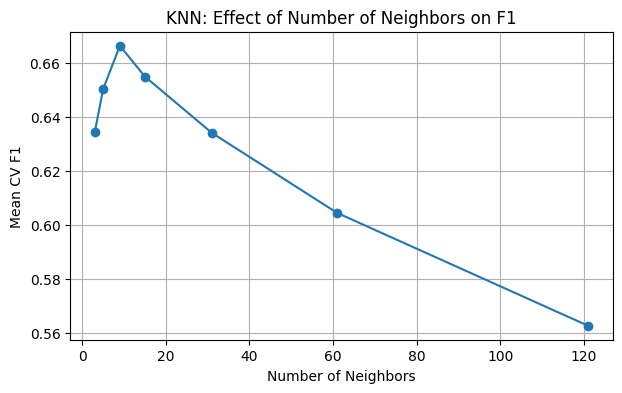

In [377]:
knn_graph = pd.DataFrame(knn_results)

knn_f1_by_neighbors = knn_graph.groupby(
    'param_classifier__n_neighbors'
)['mean_test_f1'].mean()

plt.figure(figsize=(7, 4))
plt.plot(
    knn_f1_by_neighbors.index,
    knn_f1_by_neighbors.values,
    marker='o'
)

plt.xlabel('Number of Neighbors')
plt.ylabel('Mean CV F1')
plt.title('KNN: Effect of Number of Neighbors on F1')
plt.grid(True)
plt.show()

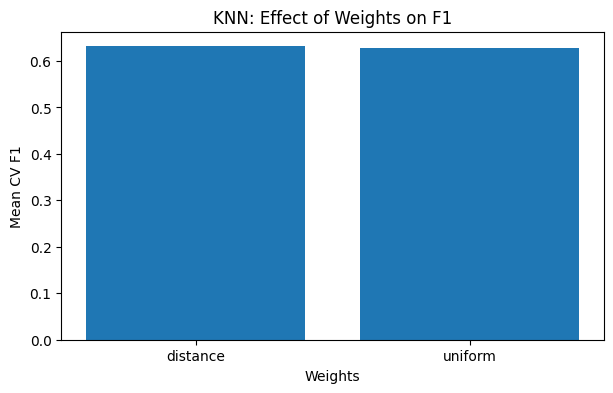

In [378]:
knn_f1_by_weights = knn_graph.groupby(
    'param_classifier__weights'
)['mean_test_f1'].mean()

plt.figure(figsize=(7, 4))
plt.bar(knn_f1_by_weights.index, knn_f1_by_weights.values)

plt.xlabel('Weights')
plt.ylabel('Mean CV F1')
plt.title('KNN: Effect of Weights on F1')
plt.show()

## 2.4.3 `KNN GridSearchCV` Interpretation

The GridSearchCV found n_neighbors = 9 and weights = uniform as the best hyperparameters for KNN, resulting in a cross-validation F1 score of 0.667. This is an improvement over the default KNN F1 of 0.650.

- The graph shows that performance peaks at 9 neighbours. After this point, the F1 score starts decreasing as more neighbours are considered.
- The choice between uniform and distance weighting has a very small effect on F1. GridSearchCV selected uniform, meaning that all 9 neighbours have the same influence on the prediction rather than giving more importance to the closest ones.
- The model has a high precision of 0.820 but a much lower recall of 0.562. This means that when KNN predicts a positive case it is usually correct, but it misses a fairly large amount of the actual positive cases.
- The mean training F1 is 0.716 compared with a cross-validation F1 of 0.667, creating a gap of 0.050. There is therefore little difference between training and validation performance.
- Overall, tuning improves KNN from an F1 of 0.650 to 0.667.

### Random forest

In [379]:
random_forest_param_grid = {
    'classifier__n_estimators': [100, 300],
    'classifier__max_depth': [6, 10, 20, None],
    'classifier__min_samples_leaf': [1, 5, 20]
}

random_forest_grid_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=random_forest_param_grid,
    scoring=scoring,
    refit='f1',
    return_train_score=True,
    cv=cv,
    n_jobs=-1
)

random_forest_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=4106))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [6, 10, ...], 'classifier__min_samples_leaf': [1, 5, ...], 'classifier__n_estimators': [100, 300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'precision', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messag

In [380]:
random_forest_best_idx = random_forest_grid_search.best_index_
random_forest_results = random_forest_grid_search.cv_results_

print("Random Forest")
print("---------------------------")

print("Best parameters:", random_forest_grid_search.best_params_)

print("\nCV Results:")
print(f"Precision: {random_forest_results['mean_test_precision'][random_forest_best_idx]:.3f} ± {random_forest_results['std_test_precision'][random_forest_best_idx]:.3f}")
print(f"Recall:    {random_forest_results['mean_test_recall'][random_forest_best_idx]:.3f} ± {random_forest_results['std_test_recall'][random_forest_best_idx]:.3f}")
print(f"F1:        {random_forest_results['mean_test_f1'][random_forest_best_idx]:.3f} ± {random_forest_results['std_test_f1'][random_forest_best_idx]:.3f}")
print(f"ROC AUC:   {random_forest_results['mean_test_roc_auc'][random_forest_best_idx]:.3f} ± {random_forest_results['std_test_roc_auc'][random_forest_best_idx]:.3f}")

random_forest_train_f1 = random_forest_results['mean_train_f1'][random_forest_best_idx]
random_forest_cv_f1 = random_forest_results['mean_test_f1'][random_forest_best_idx]

print(f"\nMean Training F1: {random_forest_train_f1:.3f}")
print(f"Train-CV F1 Gap:  {random_forest_train_f1 - random_forest_cv_f1:.3f}")

Random Forest
---------------------------
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 300}

CV Results:
Precision: 0.818 ± 0.019
Recall:    0.630 ± 0.016
F1:        0.712 ± 0.016
ROC AUC:   0.874 ± 0.015

Mean Training F1: 1.000
Train-CV F1 Gap:  0.288


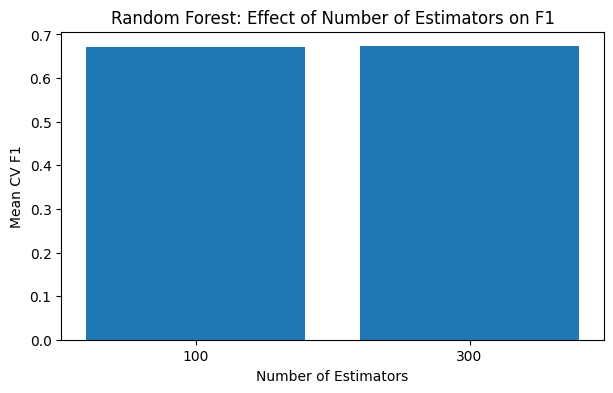

In [381]:
random_forest_graph = pd.DataFrame(random_forest_results)

random_forest_f1_by_estimators = random_forest_graph.groupby(
    'param_classifier__n_estimators'
)['mean_test_f1'].mean()

plt.figure(figsize=(7, 4))
plt.bar(
    random_forest_f1_by_estimators.index.astype(str),
    random_forest_f1_by_estimators.values
)

plt.xlabel('Number of Estimators')
plt.ylabel('Mean CV F1')
plt.title('Random Forest: Effect of Number of Estimators on F1')
plt.show()

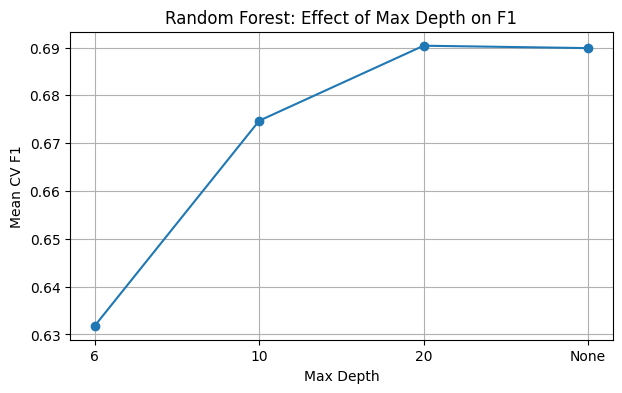

In [382]:
random_forest_graph = pd.DataFrame(random_forest_results)

random_forest_f1_by_depth = random_forest_graph.groupby(
    'param_classifier__max_depth',
    dropna=False
)['mean_test_f1'].mean()

random_forest_f1_by_depth.index = random_forest_f1_by_depth.index.map(
    lambda x: 'None' if pd.isna(x) else str(int(x))
)

plt.figure(figsize=(7, 4))
plt.plot(
    random_forest_f1_by_depth.index,
    random_forest_f1_by_depth.values,
    marker='o'
)

plt.xlabel('Max Depth')
plt.ylabel('Mean CV F1')
plt.title('Random Forest: Effect of Max Depth on F1')
plt.grid(True)
plt.show()

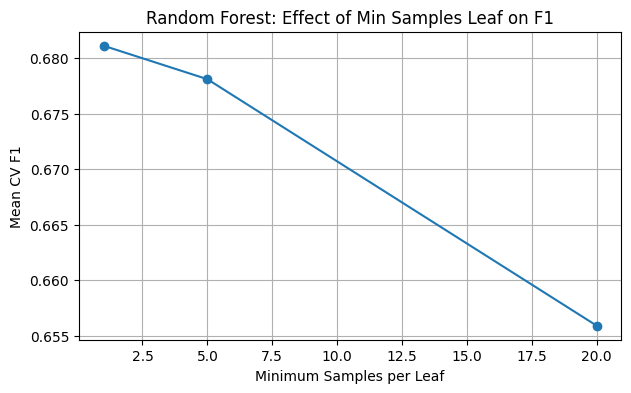

In [383]:
random_forest_f1_by_leaf = random_forest_graph.groupby(
    'param_classifier__min_samples_leaf'
)['mean_test_f1'].mean()

plt.figure(figsize=(7, 4))
plt.plot(
    random_forest_f1_by_leaf.index,
    random_forest_f1_by_leaf.values,
    marker='o'
)

plt.xlabel('Minimum Samples per Leaf')
plt.ylabel('Mean CV F1')
plt.title('Random Forest: Effect of Min Samples Leaf on F1')
plt.grid(True)
plt.show()

## 2.4.4 `Random Forest GridSearchCV` Interpretation

The GridSearchCV found max_depth = None, min_samples_leaf = 1, and n_estimators = 300 as the best hyperparameters for the Random Forest, resulting in a cross-validation F1 score of 0.712. This improves on the default Random Forest F1 of 0.699 and remains the best-performing model after tuning.

- The number of estimators has very little effect on F1, with 100 and 300 trees producing almost identical results.
- For maximum depth, performance improves as the trees are allowed to become deeper. This suggests that the Random Forest benefits from allowing its individual trees to capture more complex relationships in the data.
- For minimum samples per leaf, smaller values perform better. GridSearchCV selected min_samples_leaf = 1, allowing the individual trees to create very specific splits.
- The tuned Random Forest achieves a high precision of 0.818 and recall of 0.630, resulting in the best cross-validation F1 of 0.712 and ROC AUC of 0.874 among the tested models. 
- However, the model has a training F1 of 1.000 compared with a cross-validation F1 of 0.712, creating a very large gap of 0.288. This shows that the Random Forest fits the training data extremely closely and is likely overfitting to some degree.
- Overall, tuning improves the Random Forest from an F1 of 0.699 to 0.712.

### Final results concatenated

In [384]:
comparison_table = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Random Forest'
    ],
    
    'Precision': [
        logreg_results['mean_test_precision'][logreg_best_idx],
        decision_tree_results['mean_test_precision'][decision_tree_best_idx],
        knn_results['mean_test_precision'][knn_best_idx],
        random_forest_results['mean_test_precision'][random_forest_best_idx]
    ],
    
    'Recall': [
        logreg_results['mean_test_recall'][logreg_best_idx],
        decision_tree_results['mean_test_recall'][decision_tree_best_idx],
        knn_results['mean_test_recall'][knn_best_idx],
        random_forest_results['mean_test_recall'][random_forest_best_idx]
    ],
    
    'F1': [
        logreg_cv_f1,
        decision_tree_cv_f1,
        knn_cv_f1,
        random_forest_cv_f1
    ],
    
    'ROC AUC': [
        logreg_results['mean_test_roc_auc'][logreg_best_idx],
        decision_tree_results['mean_test_roc_auc'][decision_tree_best_idx],
        knn_results['mean_test_roc_auc'][knn_best_idx],
        random_forest_results['mean_test_roc_auc'][random_forest_best_idx]
    ],
    
    'Training F1': [
        logreg_train_f1,
        decision_tree_train_f1,
        knn_train_f1,
        random_forest_train_f1
    ]
})

comparison_table['Train-CV Gap'] = (
    comparison_table['Training F1'] - comparison_table['F1']
)

print(comparison_table.round(3).to_string(index=False))

              Model  Precision  Recall    F1  ROC AUC  Training F1  Train-CV Gap
Logistic Regression      0.580   0.692 0.631    0.788        0.633         0.002
      Decision Tree      0.705   0.600 0.648    0.810        0.778         0.130
                KNN      0.820   0.562 0.667    0.841        0.716         0.050
      Random Forest      0.818   0.630 0.712    0.874        1.000         0.288


## 2.4.5 Interpretation

The Random Forest was selected as the final classifier because it achieved the highest mean cross-validation F1 score. Its F1 standard deviation was also relatively low at ±0.016, showing that its performance was fairly consistent across the five cross-validation folds.

The Random Forest also provides a strong balance between the other evaluation metrics. It achieved a high precision of 0.818 while maintaining a recall of 0.630, and had the highest ROC AUC of all four models at 0.874. KNN achieved slightly higher precision at 0.820, while Logistic Regression achieved higher recall at 0.692, but neither provided the same overall balance of F1 and ROC AUC as the Random Forest.

One concern is the Random Forest's training F1 of 1.000 and large train-CV gap of 0.288, which suggests that the model fits the training data very closely and is likely overfitting to some degree. It is also more complex and computationally expensive than models such as Logistic Regression or a single Decision Tree because it trains and combines many trees. However, model selection is primarily based on performance on unseen validation folds rather than training performance, and the Random Forest still achieved the strongest and relatively stable cross-validation F1.

The final pipeline therefore uses the `basePreprocessor` with a Random Forest configured with `n_estimators=300`, `max_depth=None`, and `min_samples_leaf=1`. Although this configuration has a higher computational cost and greater model complexity, its stronger cross-validation F1, high precision, and highest ROC AUC make it the strongest overall choice among the four tested classifier families.

## 2.5 Select and test one final model

Compare the default and tuned results. Select exactly one classifier
family and one associated preprocessing and hyperparameter
configuration; together, these choices are your final pipeline. Record
its mean cross-validation F1 to at least four decimal places before
evaluating it once on the untouched complete test partition. Report
precision, recall, F1, ROC AUC, and a labelled confusion matrix. Compare
cross-validation and test performance, then discuss one limitation of
choosing a model primarily by F1.

## 2.5.1 Computations

In [385]:
default_cv_f1 = random_forest_scores["test_f1"].mean()
default_cv_f1_std = random_forest_scores["test_f1"].std()

tuned_cv_f1 = random_forest_grid_search.best_score_

print(f"Default Random Forest CV F1: {default_cv_f1:.4f} ± {default_cv_f1_std:.4f}")
print(f"Tuned Random Forest CV F1:   {tuned_cv_f1:.4f}")
print(f"Best hyperparameters: {random_forest_grid_search.best_params_}")

Default Random Forest CV F1: 0.6990 ± 0.0125
Tuned Random Forest CV F1:   0.7115
Best hyperparameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 300}


In [386]:
final_pipeline = random_forest_grid_search.best_estimator_

final_cv_f1 = random_forest_grid_search.best_score_

print(f"Final selected CV F1: {final_cv_f1:.4f}")

Final selected CV F1: 0.7115


In [387]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [388]:
y_pred = final_pipeline.predict(X_test)
y_prob = final_pipeline.predict_proba(X_test)[:, 1]

test_precision = precision_score(y_test, y_pred)
test_recall = recall_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, y_prob)

print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1:        {test_f1:.4f}")
print(f"ROC AUC:   {test_roc_auc:.4f}")

Precision: 0.8100
Recall:    0.6265
F1:        0.7065
ROC AUC:   0.8797


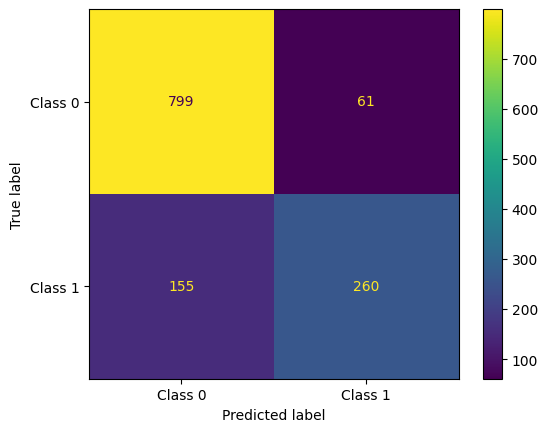

In [389]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

disp.plot()

In [390]:
print(f"Cross-validation F1: {final_cv_f1:.4f}")
print(f"Test F1:             {test_f1:.4f}")
print(f"Difference:          {abs(test_f1 - final_cv_f1):+.4f}")

Cross-validation F1: 0.7115
Test F1:             0.7065
Difference:          +0.0050


## 2.5.1 Interpretation

The chosen model was Random Forest with 
- basePreprocesser
- classifier__max_depth': None,
- 'classifier__min_samples_leaf': 1,
- 'classifier__n_estimators': 300

#### Graph
- The confusion matrix shows that the model performs particularly well at identifying Class 0, correctly classifying 799 observations while only incorrectly classifying 61 as Class 1. For Class 1, it correctly identifies 260 observations but misses 155. This explains the model's high precision of 0.810 but lower recall of 0.627. The model therefore appears more conservative when predicting Class 1, producing relatively few false positives at the cost of more false negatives.

#### Testing F1 results 
- The final Random Forest achieved a cross-validation F1 of 0.7115 and a test F1 of 0.7065, a difference of only 0.0050. This difference is very small and shows that the model performs almost as well on the completely untouched test data as it did during cross-validation.
- Considering that the model had a perfect training F1 of 1.000 and showed signs of overfitting during training, it is lovely to see confirmation that it was not an issue afterall.
- Overall, the test results support the selection of Random Forest as the final model, as its performance remained stable when evaluated on completely unseen data.

#### Limitation of selecting a model by F1
- One limitation of selecting a model primarily by F1 is that F1 combines precision and recall into a single score, which can hide the types of mistakes the model is making. For example, the final Random Forest has a good F1 of 0.7065, but its precision is much higher at 0.8100 than its recall at 0.6265. The confusion matrix shows that the model misses 155 actual positive cases while only producing 61 false positives. Depending on the problem, missing positive cases could be much more costly than incorrectly predicting a positive case. 

## 2.6 Evaluate the effect of missing values

2.6.1: Summarize missingness by predictor, across all predictor cells, and by
mission. 

2.6.2: Apply the saved split to the cleaned data.

2.6.3: Add the required imputation inside the pipeline and compare the complete and cleaned
versions using the selected model, fixed hyperparameters, development
rows, and identical folds. Report fold-by-fold differences, computed as
cleaned minus complete, and their means for every required metric.

## 2.6.1 Computations

Missing value counts per predictor

In [391]:
dfClean.isna().sum()

planned_depth_m                6
descent_current_speed_m_s      6
water_temperature_c          169
sonar_noise_db               123
navigation_drift_m           120
battery_health_pct           153
thruster_vibration_mm_s      126
missions_since_service         0
vehicle_class                  0
seabed_terrain                 0
maintenance_grade            129
firmware_current               0
mission_interrupted            0
dtype: int64

Missing value percentages per predictor

In [392]:
print((dfClean.isna().sum() / len(dfClean) * 100).round(3).astype(str) + '%')

planned_depth_m              0.094%
descent_current_speed_m_s    0.094%
water_temperature_c          2.653%
sonar_noise_db               1.931%
navigation_drift_m           1.884%
battery_health_pct           2.402%
thruster_vibration_mm_s      1.978%
missions_since_service         0.0%
vehicle_class                  0.0%
seabed_terrain                 0.0%
maintenance_grade            2.025%
firmware_current               0.0%
mission_interrupted            0.0%
dtype: str


Overall missing values (predictor cells) count

In [393]:
dfClean.isna().sum().sum()

np.int64(832)

Overall missing values (predictor cells) percentage across all values

In [394]:
print((dfClean.isna().sum().sum() / (len(dfClean) * len(dfClean.columns)) * 100).round(3).astype(str) + '%')

1.005%


In [395]:
dfClean.shape

(6371, 13)

Missing value counts (0, 1 and 2 or more)

In [396]:
missing_per_row = dfClean.isna().sum(axis=1)

no_missing_df = dfClean[missing_per_row == 0]
one_missing_df = dfClean[missing_per_row == 1]
two_plus_df = dfClean[missing_per_row >= 2]

print(f"Rows with NO missing values: {len(no_missing_df):,}")
print(f"Rows with exactly ONE missing value: {len(one_missing_df):,}")
print(f"Rows with TWO OR MORE missing cells: {len(two_plus_df):,}")

Rows with NO missing values: 5,579
Rows with exactly ONE missing value: 752
Rows with TWO OR MORE missing cells: 40


Missing value percentages (0, 1 and 2 or more)

In [397]:
missing_per_row = dfClean.isna().sum(axis=1)

pct_no_missing = (missing_per_row == 0).mean() * 100
pct_one_missing = (missing_per_row == 1).mean() * 100
pct_two_plus = (missing_per_row >= 2).mean() * 100

print(f"% of rows with NO missing values: {pct_no_missing:.3f}%")
print(f"% of rows with exactly ONE missing value: {pct_one_missing:.3f}%")
print(f"% of rows with TWO OR MORE missing cells: {pct_two_plus:.3f}%")

% of rows with NO missing values: 87.569%
% of rows with exactly ONE missing value: 11.803%
% of rows with TWO OR MORE missing cells: 0.628%


## 2.6.1 Interpretation

- Some columns contain no missing values whereas some contain up to 2.6%. Across all values in the dataset, a little over 1% of them are missing.
- 87.5% of all rows are unaffected by missing values and are completely identical to the Complete dataset.

## 2.6.2 Computations

In [398]:
clean_train = dfClean.loc[train_indices]
clean_test = dfClean.loc[test_indices]

In [399]:
print((clean_train["mission_interrupted"] == y_train).all())
print((clean_test["mission_interrupted"] == y_test).all())

True
True


## 2.6.2 Interpretation

The computations show that the same training indices in both datasets return the same target values

## 2.6.3 Computations

In [400]:
from sklearn.impute import SimpleImputer

All the new pipelines, with the same winning basePreprocessing techniques and with imputers included

In [401]:
numericalPreprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [402]:
nominalPreprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))
])

In [403]:
binaryPreprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

In [404]:
ordinalPreprocessors = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[['poor', 'fair', 'good', 'excellent']]))
])

Aggregating the new preprocessors

In [405]:
cleanPreprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numericalPreprocessor, numerical),
        ('nominal', nominalPreprocessor, nominal),
        ('binary', binaryPreprocessor, binary),
        ('ordinal', nominalPreprocessor, ordinal)
    ]
)

Pipelining the imputed pipelines with our winning hyperparameters

In [406]:
cleanPipeline = Pipeline([
    ('preprocessor', cleanPreprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=1,
        random_state=4106
    ))
])

In [407]:
X_train_clean = clean_train.drop(columns=['mission_interrupted'])
y_train_clean = clean_train['mission_interrupted']

In [408]:
cleaned_forest_scores = cross_validate(
    cleanPipeline,
    X_train_clean,
    y_train_clean,
    cv=cv,
    scoring=scoring
)

cleaned_forest_results = {}

Cleaned vs Original (Complete) Dataset CV individual scores

In [409]:
for metric in scoring:
    complete_scores = random_forest_scores[f"test_{metric}"]
    cleaned_scores = cleaned_forest_scores[f"test_{metric}"]

    differences = cleaned_scores - complete_scores

    print(f"\n{metric.capitalize()}:")
    print("Complete:   ", complete_scores.round(4))
    print("Cleaned:    ", cleaned_scores.round(4))
    print("Difference: ", differences.round(4))
    print(f"Mean difference: {differences.mean():.3f}")


Accuracy:
Complete:    [0.8382 0.8194 0.8283 0.8263 0.8194]
Cleaned:     [0.8451 0.8273 0.8283 0.84   0.8184]
Difference:  [ 0.0069  0.0079  0.      0.0137 -0.001 ]
Mean difference: 0.005

Precision:
Complete:    [0.8256 0.7868 0.8008 0.8163 0.7868]
Cleaned:     [0.8405 0.8    0.794  0.834  0.786 ]
Difference:  [ 0.0149  0.0132 -0.0068  0.0177 -0.0008]
Mean difference: 0.008

Recall:
Complete:    [0.6396 0.6114 0.6295 0.6024 0.6114]
Cleaned:     [0.6486 0.6265 0.6386 0.6355 0.6084]
Difference:  [ 0.009   0.0151  0.009   0.0331 -0.003 ]
Mean difference: 0.013

F1:
Complete:    [0.7208 0.6881 0.7049 0.6932 0.6881]
Cleaned:     [0.7322 0.7027 0.7078 0.7214 0.6859]
Difference:  [ 0.0114  0.0146  0.003   0.0281 -0.0022]
Mean difference: 0.011

Roc_auc:
Complete:    [0.8936 0.8671 0.8601 0.8712 0.8577]
Cleaned:     [0.8942 0.8719 0.8672 0.8777 0.8535]
Difference:  [ 0.0006  0.0049  0.0071  0.0065 -0.0041]
Mean difference: 0.003


## 2.6.3 Interpretation

The imputed dataset generally performed slightly better than the complete dataset, with positive differences appearing in most folds and metrics. The magnitude of these differences was small overall, with recall and F1 showing the largest improvements and ROC AUC showing very little change. There was also some variability between folds, as the complete dataset occasionally performed better. Overall, imputation did not reduce performance and instead produced small improvements in most folds, while keeping performance relatively consistent with the complete dataset.

## 2.7 Produce predictions for the hidden missions

2.7.1: Load the hidden data into a DataFrame named `hidden_missions`; do not
change this name. 

2.7.2: Refit the locked complete-data pipeline on all
labelled missions and generate `asrc_missions_hidden_predictions.csv`
with exactly the required columns. Do not round probabilities before
saving them. Validate the mission IDs, classes, class-probability
consistency, and row order. State to at least four decimal places the
cross-validation F1 associated with this exact pipeline. Consult the
handout for the allocation of the two hidden-prediction marks.

2.7.3: Computations on unseen data and predictions graph visualisation

## 2.7.1 Computations

In [410]:
hidden_missions = pd.read_csv("https://raw.githubusercontent.com/turcotte/csi4106-f26/main/assignments-data/a2/asrc_missions_hidden.csv")

## 2.7.2 Computations

In [411]:
X_full = pd.concat([X_train, X_test])
y_full = pd.concat([y_train, y_test])

In [412]:
final_pipeline.fit(X_full, y_full)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('onehotBin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differ

In [413]:
hidden_missions.shape

(2124, 13)

In [414]:
print(len(hidden_predictions) == 2124)

True


In [415]:
print(hidden_predictions["mission_id"].is_unique)

True


In [416]:
print(hidden_predictions["predicted_class"].isin([0, 1]).all())

True


In [417]:
print(hidden_predictions["predicted_probability"].between(0, 1).all())

True


In [418]:
expected_classes = (hidden_predictions["predicted_probability"] > 0.5).astype(int)

print(
    (hidden_predictions["predicted_class"] == expected_classes).all()
)

True


In [419]:
print(
    hidden_predictions["mission_id"].reset_index(drop=True).equals(
        hidden_missions["mission_id"].reset_index(drop=True)
    )
)

True


In [420]:
hidden_missions.index

RangeIndex(start=0, stop=2124, step=1)

In [421]:
hidden_missions.columns

Index(['mission_id', 'planned_depth_m', 'descent_current_speed_m_s',
       'water_temperature_c', 'sonar_noise_db', 'navigation_drift_m',
       'battery_health_pct', 'thruster_vibration_mm_s',
       'missions_since_service', 'vehicle_class', 'seabed_terrain',
       'maintenance_grade', 'firmware_current'],
      dtype='str')

## 2.7.2 Interpretation

The final pipeline was refitted using all labelled complete-data missions before generating predictions for the 2,124 hidden missions. The validation checks confirmed that all mission IDs are unique, predicted classes are valid, probabilities fall between 0 and 1, predicted classes agree with the default classification threshold, and the original hidden mission row order was preserved.

## 2.7.3 Computations

In [422]:
mission_ids = hidden_missions["mission_id"]
X_hidden = hidden_missions.drop(columns=["mission_id"])

predicted_class = final_pipeline.predict(X_hidden)
predicted_probability = final_pipeline.predict_proba(X_hidden)[:, 1]

hidden_predictions = pd.DataFrame({
    "mission_id": mission_ids,
    "predicted_class": predicted_class,
    "predicted_probability": predicted_probability
})

hidden_predictions.to_csv(
    "asrc_missions_hidden_predictions.csv",
    index=False
)

print("Hidden mission predictions saved successfully.")
print(f"Number of predictions: {len(hidden_predictions)}")
print("\nFirst 5 predictions:")
print(hidden_predictions.head())

Hidden mission predictions saved successfully.
Number of predictions: 2124

First 5 predictions:
     mission_id  predicted_class  predicted_probability
0  ASRC-H000001                1               0.720000
1  ASRC-H000002                0               0.390000
2  ASRC-H000003                1               0.890000
3  ASRC-H000004                1               0.790000
4  ASRC-H000005                0               0.036667


In [423]:
import matplotlib.pyplot as plt

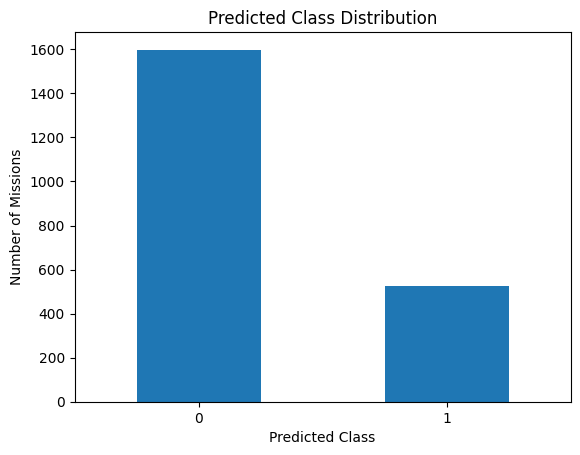

In [424]:
# 1. Predicted class distribution
hidden_predictions["predicted_class"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Predicted Class Distribution")
plt.xlabel("Predicted Class")
plt.ylabel("Number of Missions")
plt.xticks(rotation=0)
plt.show()

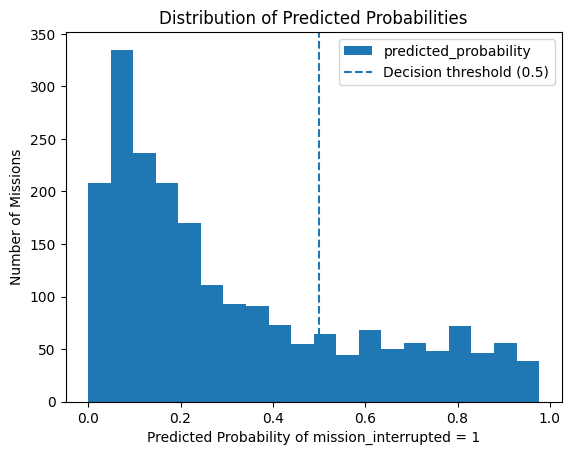

In [425]:
# 2. Distribution of predicted probabilities
hidden_predictions["predicted_probability"].plot(
    kind="hist",
    bins=20
)

plt.axvline(0.5, linestyle="--", label="Decision threshold (0.5)")
plt.title("Distribution of Predicted Probabilities")
plt.xlabel("Predicted Probability of mission_interrupted = 1")
plt.ylabel("Number of Missions")
plt.legend()
plt.show()

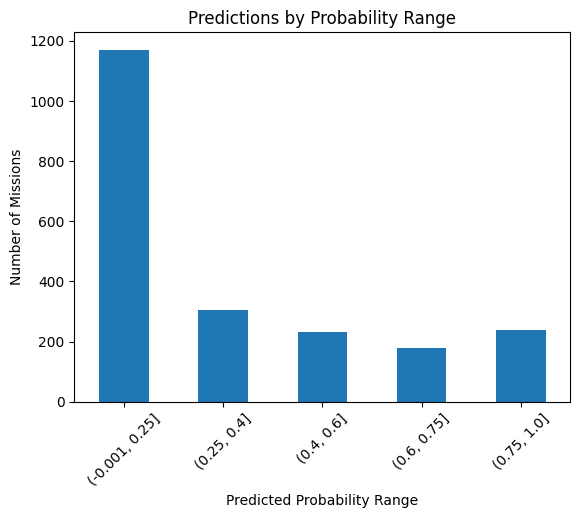

In [426]:
# 3. Count predictions by probability range
probability_groups = pd.cut(
    hidden_predictions["predicted_probability"],
    bins=[0, 0.25, 0.4, 0.6, 0.75, 1],
    include_lowest=True
)

probability_groups.value_counts(sort=False).plot(kind="bar")

plt.title("Predictions by Probability Range")
plt.xlabel("Predicted Probability Range")
plt.ylabel("Number of Missions")
plt.xticks(rotation=45)
plt.show()

In [427]:
print("Hidden Prediction Summary")
print("-------------------------")
print(hidden_predictions["predicted_class"].value_counts().sort_index())
print()
print(hidden_predictions["predicted_probability"].describe())

Hidden Prediction Summary
-------------------------
predicted_class
0    1598
1     526
Name: count, dtype: int64

count    2124.000000
mean        0.316899
std         0.270256
min         0.000000
25%         0.096667
50%         0.216667
75%         0.497500
max         0.976667
Name: predicted_probability, dtype: float64


## 2.7.3 Interpretation

The model predicted 526 of the 2,124 hidden missions as interrupted (class 1) and 1,598 as not interrupted (class 0). Predicted probabilities are concentrated toward the lower end, with a median of about 0.217, which agrees with the larger number of class 0 predictions. However, probabilities span almost the full 0–1 range, showing that the model also produced some high-confidence interruption predictions. Since the true hidden labels are unavailable, these plots describe the model's predictions but cannot be used to determine its actual performance on the hidden data.

The following function validates only the saved file’s format and
internal consistency. It does not generate predictions or provide
information about hidden-set performance.

In [428]:
import pandas as pd


def validate_hidden_prediction_file(path, hidden_missions):
    predictions = pd.read_csv(path)
    expected_columns = [
        "mission_id",
        "predicted_class",
        "predicted_probability",
    ]

    assert list(predictions.columns) == expected_columns, (
        f"Expected columns {expected_columns}, "
        f"but found {list(predictions.columns)}"
    )
    assert len(predictions) == len(hidden_missions), (
        f"Expected {len(hidden_missions)} rows, "
        f"but found {len(predictions)}"
    )
    assert predictions["mission_id"].is_unique, (
        "Each mission_id must occur exactly once"
    )

    submitted_ids = predictions["mission_id"].reset_index(drop=True)
    expected_ids = hidden_missions["mission_id"].reset_index(drop=True)
    assert submitted_ids.equals(expected_ids), (
        "mission_id values or row order do not match the hidden data"
    )
    assert predictions["predicted_class"].isin([0, 1]).all(), (
        "predicted_class must contain only 0 and 1"
    )

    probabilities = pd.to_numeric(
        predictions["predicted_probability"], errors="coerce"
    )
    assert probabilities.notna().all(), (
        "predicted_probability must be numeric and complete"
    )
    assert probabilities.between(0, 1).all(), (
        "predicted_probability values must lie between 0 and 1"
    )
    expected_classes = (probabilities > 0.5).astype(int)
    assert predictions["predicted_class"].astype(int).equals(
        expected_classes
    ), (
        "predicted_class does not agree with predicted_probability "
        "at the default threshold"
    )

    print("Prediction file structure is valid.")
    return predictions



validate_hidden_prediction_file(
     "asrc_missions_hidden_predictions.csv", hidden_missions
)

Prediction file structure is valid.


,mission_id,predicted_class,predicted_probability
0,ASRC-H000001,1,0.720000
1,ASRC-H000002,0,0.390000
2,ASRC-H000003,1,0.890000
3,ASRC-H000004,1,0.790000
4,ASRC-H000005,0,0.036667
...,...,...,...
2119,ASRC-H002120,1,0.606667
2120,ASRC-H002121,0,0.050000
2121,ASRC-H002122,1,0.503333
2122,ASRC-H002123,1,0.646667


[1] The pandas development team, “pandas documentation,” *pandas*, ver. 3.1.0. [Online]. Available: [https://pandas.pydata.org/pandas-docs/stable/index.html](https://pandas.pydata.org/pandas-docs/stable/index.html). [Accessed: Oct. 21, 2026].

[2] The scikit-learn developers, “scikit-learn: Machine Learning in Python,” *scikit-learn*, ver. 1.9.1. [Online]. Available: [https://scikit-learn.org/stable/index.html](https://scikit-learn.org/stable/index.html). [Accessed: Oct. 21, 2026].